In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split 
from joblib import dump, load
from tensorflow.keras.models import Model 
from tensorflow.keras.layers import Input, Dense
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "C:\ProgramData\anaconda3\envs\ids_env\lib\runpy.py", line 196, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "C:\ProgramData\anaconda3\envs\ids_env\lib\runpy.py", line 86, in _run_code
    exec(code, run_globals)
  File "C:\ProgramData\anaconda3\envs\ids_env\lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\ProgramData\anaconda3\envs\ids_env\lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.s

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "C:\ProgramData\anaconda3\envs\ids_env\lib\runpy.py", line 196, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "C:\ProgramData\anaconda3\envs\ids_env\lib\runpy.py", line 86, in _run_code
    exec(code, run_globals)
  File "C:\ProgramData\anaconda3\envs\ids_env\lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\ProgramData\anaconda3\envs\ids_env\lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.s

AttributeError: _ARRAY_API not found

ImportError: numpy.core._multiarray_umath failed to import

ImportError: numpy.core.umath failed to import

TypeError: Unable to convert function return value to a Python type! The signature was
	() -> handle

In [2]:
COLUMNS = ['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 
           'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dnpkt', 'sjit', 'djit', 
           'swin', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 
           'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 
           'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 
           'is_sm_ips_ports', 'attack_cat', 'label']

file_list = ['UNSW-NB15_1.csv', 'UNSW-NB15_2.csv', 'UNSW-NB15_3.csv', 'UNSW-NB15_4.csv']
list_of_dfs = []

print("Start Merging Files")



try:
    for filename in file_list:
        df = pd.read_csv(filename, header=None, names=COLUMNS)
        list_of_dfs.append(df)
    
    combined_df = pd.concat(list_of_dfs, ignore_index=True)
    print(f"Merge all files successfully and the size is : {combined_df.shape}")
except FileNotFoundError:
    print(f" I can't find some file : {file_list}")
    raise

Start Merging Files
Merge all files successfully and the size is : (2540047, 43)


In [3]:
def preprocess_data(df):
    
    df.replace(['-', ' ', np.inf, -np.inf], np.nan, inplace=True) 
    df.drop(['id'], axis=1, inplace=True, errors='ignore') 

    categorical_features = ['proto', 'service', 'state']
    for col in categorical_features:
        if col in df.columns:
            df[col] = df[col].astype(str).astype('category').cat.codes
        
    feature_cols_temp = [col for col in df.columns if col not in ['label', 'attack_cat']]

    cols_to_keep = []
    for col in feature_cols_temp:
        df[col] = pd.to_numeric(df[col], errors='coerce') 
        if df[col].isna().all():
            print(f"   Warning the '{col}' Deleted completly because it was empty")
            df.drop(col, axis=1, inplace=True)
        else:
            cols_to_keep.append(col)    
    feature_cols_final = cols_to_keep
    df.dropna(subset=feature_cols_final, inplace=True)
    return df, feature_cols_final
    
combined_df_cleaned, feature_cols = preprocess_data(combined_df.copy())
print(f"The Size of Data after Cleanning: {combined_df_cleaned.shape}")


   Warning the 'sbytes' Deleted completly because it was empty
The Size of Data after Cleanning: (1087203, 41)


In [4]:
TEST_SIZE_RATIO = 0.3
SEED = 42
df_train_cleaned, df_test_cleaned = train_test_split(
    combined_df_cleaned, 
    test_size=TEST_SIZE_RATIO, 
    random_state=SEED, 
    shuffle=True,
    stratify=combined_df_cleaned['label'] 
)

print(f"The data has been split")
print(f"Size of Train Set (df_train_cleaned): {df_train_cleaned.shape}")
print(f"Size of Test Set (df_test_cleaned): {df_test_cleaned.shape}")

The data has been split
Size of Train Set (df_train_cleaned): (761042, 41)
Size of Test Set (df_test_cleaned): (326161, 41)


In [5]:
scaler = MinMaxScaler()

X_train_features = scaler.fit_transform(df_train_cleaned[feature_cols])
X_test_features = scaler.transform(df_test_cleaned[feature_cols])
X_train_df = pd.DataFrame(X_train_features, columns=feature_cols)
X_test_df = pd.DataFrame(X_test_features, columns=feature_cols)

dump(scaler, 'scaler_unsw_nb15.joblib')
print(" Saving MinMaxScaler Object gone just right")
train_labels = df_train_cleaned['label'].reset_index(drop=True)
X_train_ae = X_train_df[train_labels == 0].reset_index(drop=True) 

if X_train_ae.shape[0] > 1:
    X_train_ae, X_test_ae_val = train_test_split(X_train_ae, test_size=0.2, random_state=42)
else:
    X_test_ae_val = pd.DataFrame() 
    print("The number of natural samples are small for splliting")

y_train_cat_original = df_train_cleaned['attack_cat'].reset_index(drop=True)
y_test_cat_original = df_test_cleaned['attack_cat'].reset_index(drop=True)

print(f"Size of Autoencoder Train Data Set is: {X_train_ae.shape}")
print(f"Size of overall Train Data Set is: {X_train_df.shape}")
print(f"Size of overall Test Data Set is: {X_test_df.shape}")

 Saving MinMaxScaler Object gone just right
Size of Autoencoder Train Data Set is: (596393, 39)
Size of overall Train Data Set is: (761042, 39)
Size of overall Test Data Set is: (326161, 39)


In [6]:
print("Start Trainning Autoencoder")

input_dim = X_train_ae.shape[1] 

input_layer = Input(shape=(input_dim,))
encoder = Dense(128, activation='relu')(input_layer)
encoder = Dense(64, activation='relu')(encoder)
bottleneck = Dense(32, activation='relu')(encoder) # Bottel Neck
decoder = Dense(64, activation='relu')(bottleneck)
decoder = Dense(128, activation='relu')(decoder)
decoder_output = Dense(input_dim, activation='sigmoid')(decoder)

autoencoder = Model(inputs=input_layer, outputs=decoder_output)
autoencoder.compile(optimizer='adam', loss='mean_squared_error')

history_ae = autoencoder.fit(X_train_ae, X_train_ae,
                              epochs=50, 
                              batch_size=512,
                              shuffle=True,
                              validation_data=(X_test_ae_val, X_test_ae_val),
                              verbose=0) 

autoencoder.save('autoencoder_model.keras')
predictions_ae = autoencoder.predict(X_test_ae_val, verbose=0)
mse_ae = np.mean(np.power(X_test_ae_val - predictions_ae, 2), axis=1)
THRESHOLD = np.quantile(mse_ae, 0.95) 

print("Autoencoder Results")
print(f"Threshold is (THRESHOLD) Based on rebuild error : {THRESHOLD:.6f}")
print("Autoencoder Saved")

Start Trainning Autoencoder
Autoencoder Results
Threshold is (THRESHOLD) Based on rebuild error : 0.000040
Autoencoder Saved


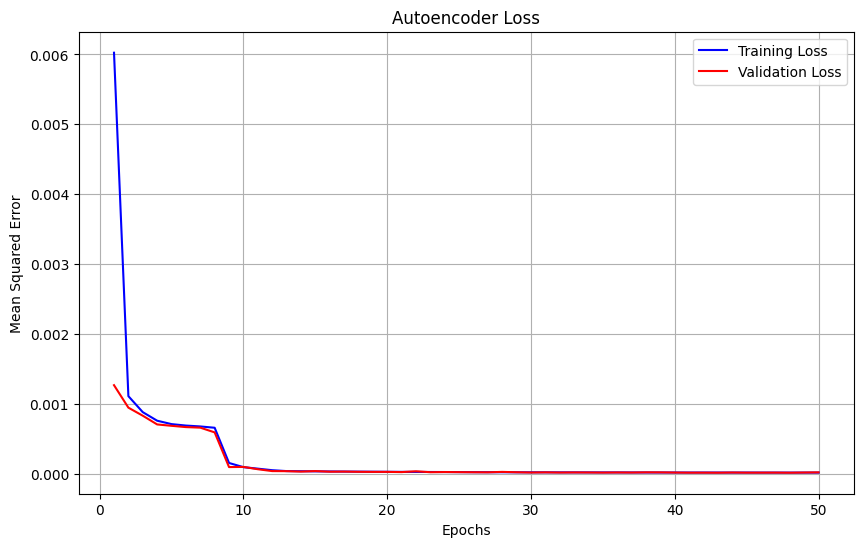

In [7]:
if 'history_ae' in locals():
    
    loss = history_ae.history['loss']
    val_loss = history_ae.history['val_loss']
    epochs = range(1, len(loss) + 1)
    
    plt.figure(figsize=(10, 6))
    plt.plot(epochs, loss, 'b', label='Training Loss')
    plt.plot(epochs, val_loss, 'r', label='Validation Loss')
    plt.title('Autoencoder Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Mean Squared Error')
    plt.legend()
    plt.grid(True)
    plt.show()

else:
    print("Some Error")

In [8]:
from tensorflow.keras.models import load_model
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical
try:
    autoencoder = load_model('autoencoder_model.keras')
except:
    autoencoder = load_model('autoencoder_model.h5')

predictions_train = autoencoder.predict(X_train_df, verbose=0)
mse_train = np.mean(np.power(X_train_df - predictions_train, 2), axis=1)

predictions_test = autoencoder.predict(X_test_df, verbose=0)
mse_test = np.mean(np.power(X_test_df - predictions_test, 2), axis=1)

is_attack_train = (mse_train > THRESHOLD).astype(int)
is_attack_test = (mse_test > THRESHOLD).astype(int)

X_classifier_train = X_train_df[is_attack_train == 1].reset_index(drop=True)
y_classifier_train_cat = y_train_cat_original[is_attack_train == 1].reset_index(drop=True)

X_classifier_test = X_test_df[is_attack_test == 1].reset_index(drop=True)
y_classifier_test_cat = y_test_cat_original[is_attack_test == 1].reset_index(drop=True)

y_classifier_train_cat = y_classifier_train_cat[y_classifier_train_cat != 'Normal']
y_classifier_test_cat = y_classifier_test_cat[y_classifier_test_cat != 'Normal']

X_classifier_train = X_classifier_train.iloc[y_classifier_train_cat.index]
X_classifier_test = X_classifier_test.iloc[y_classifier_test_cat.index]

label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_classifier_train_cat)
y_test_encoded = label_encoder.transform(y_classifier_test_cat)

y_train_one_hot = to_categorical(y_train_encoded)
y_test_one_hot = to_categorical(y_test_encoded)

dump(label_encoder, 'label_encoder_attacks.joblib')

print(f"Summarize the classifier data")
print(f"Classifier training data size : {X_classifier_train.shape}")
print(f" Number of attack categories coded: {len(label_encoder.classes_)}")
print(f"   Kinds of discover attacks : {label_encoder.classes_}")

Summarize the classifier data
Classifier training data size : (52289, 39)
 Number of attack categories coded: 10
   Kinds of discover attacks : [' Fuzzers' 'Analysis' 'Backdoors' 'DoS' 'Exploits' 'Generic'
 'Reconnaissance' 'Shellcode' 'Worms' nan]


In [9]:
from tensorflow.keras.layers import Conv1D, MaxPooling1D, LSTM, Flatten
print("Starting CNN + LSTM")

N_FEATURES = X_classifier_train.shape[1]

X_train_cl_3d = X_classifier_train.values.reshape(X_classifier_train.shape[0], N_FEATURES, 1)
X_test_cl_3d = X_classifier_test.values.reshape(X_classifier_test.shape[0], N_FEATURES, 1)

num_classes = y_train_one_hot.shape[1]
input_shape = (N_FEATURES, 1)
input_cl = Input(shape=input_shape)

conv = Conv1D(filters=64, kernel_size=3, activation='relu')(input_cl)
conv = Conv1D(filters=32, kernel_size=3, activation='relu')(conv)
lstm = LSTM(32, return_sequences=False)(conv)

# Dense Output
dense = Dense(64, activation='relu')(lstm)
output_cl = Dense(num_classes, activation='softmax')(dense)

hybrid_classifier = Model(inputs=input_cl, outputs=output_cl)
hybrid_classifier.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history_cl = hybrid_classifier.fit(
    X_train_cl_3d, y_train_one_hot,
    epochs=25, 
    batch_size=512,
    validation_data=(X_test_cl_3d, y_test_one_hot),
    verbose=1)

hybrid_classifier.save('hybrid_classifier_model.keras')
print("Trainning and Saving CNN + LSTM")

Starting CNN + LSTM
Epoch 1/25
103/103 ━━━━━━━━━━━━━━━━━━━━ 16s 103ms/step - accuracy: 0.7022 - loss: 1.3309 - val_accuracy: 0.7116 - val_loss: 1.0607
Epoch 2/25
103/103 ━━━━━━━━━━━━━━━━━━━━ 10s 95ms/step - accuracy: 0.7392 - loss: 0.8595 - val_accuracy: 0.7890 - val_loss: 0.6193
Epoch 3/25
103/103 ━━━━━━━━━━━━━━━━━━━━ 10s 94ms/step - accuracy: 0.7959 - loss: 0.5964 - val_accuracy: 0.8066 - val_loss: 0.5601
Epoch 4/25
103/103 ━━━━━━━━━━━━━━━━━━━━ 10s 93ms/step - accuracy: 0.8135 - loss: 0.5414 - val_accuracy: 0.8235 - val_loss: 0.5120
Epoch 5/25
103/103 ━━━━━━━━━━━━━━━━━━━━ 10s 94ms/step - accuracy: 0.8283 - loss: 0.5034 - val_accuracy: 0.8377 - val_loss: 0.4914
Epoch 6/25
103/103 ━━━━━━━━━━━━━━━━━━━━ 10s 93ms/step - accuracy: 0.8441 - loss: 0.4677 - val_accuracy: 0.8529 - val_loss: 0.4465
Epoch 7/25
103/103 ━━━━━━━━━━━━━━━━━━━━ 10s 93ms/step - accuracy: 0.8555 - loss: 0.4231 - val_accuracy: 0.8508 - val_loss: 0.4159
Epoch 8/25
103/103 ━━━━━━━━━━━━━━━━━━━━ 10s 92ms/step - accuracy: 0.8

In [10]:
import tensorflow as tf
print("إصدار TensorFlow:", tf.__version__)
print("هل يتوفر GPU؟:", tf.config.list_physical_devices('GPU'))

# يجب أن تكون النتيجة: 'GPU' في القائمة (مثلاً: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')])

إصدار TensorFlow: 2.20.0
هل يتوفر GPU؟: []
